# Phase 5: MLOps & LLMOps
## Notebook 04: CI/CD Pipelines, Automated Testing & Model Registry

### Overview
Traditional software CI/CD validates deterministic code paths. AI/ML CI/CD must continuously validate **three moving axes** simultaneously — **Code + Data + Weights**:
1. **Behavioral & Invariant Model Testing**: Standard unit tests check syntax, whereas ML behavioral tests (Ribeiro et al., 2020) assert **Minimum Functionality**, **Invariance** (e.g., whitespace/casing changes should not alter intent), **Directional Expectation**, and **Latency SLO Budgets**.
2. **Notebook Execution Quality Gates**: Ensuring every curriculum or research `.ipynb` runs cleanly top-to-bottom in CI with zero empty cells, schema errors, or uncaught tracebacks.
3. **Content-Addressed Model Registry**: Immutable `SHA-256` artifact hashing, Semantic Versioning (`MAJOR.MINOR.PATCH`), lineage metadata, and staged promotion (`Candidate` $\to$ `Staging` $\to$ `Production`).
4. **Canary Deployment & Statistical Auto-Rollback**: Gradually shifting traffic ($5\% \to 25\% \to 100\%$) with automated rollback gates if error rate or p99 latency regresses.

### System Architecture: ML CI/CD & Canary Promotion Pipeline
```
  [Git Push / PR] ---> [GitHub Actions CI Gate]
                            |-- 1. Lint & Type Check (ruff, mypy)
                            |-- 2. pytest Behavioral & Latency Suite
                            |-- 3. nbformat Notebook Execution Gate
                            v
                  [Model Registry (SHA-256)]
                  - v1.2.0 (Production Baseline)
                  - v1.3.0 (Candidate -> Staging)
                            |
                            v
                  [Canary Traffic Controller]
                  - 90% Baseline (v1.2.0) | 10% Canary (v1.3.0)
                            |
              +-------------+-------------+
              |                           |
     (Metrics Healthy)           (Error / Latency Spike)
              |                           |
              v                           v
    [Promote v1.3.0 to 100%]    [Instant Rollback to v1.2.0]
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **GitHub Actions MLOps Workflows**: Author and schema-validate production CI/CD YAML workflows for Python linting, `pytest` execution, notebook verification, and staged Docker rollouts.
- **Automated `pytest` Behavioral Testing**: Build and execute real `pytest` suites verifying model output invariants, non-NaN numerical guarantees, prompt invariance, and latency budgets.
- **Notebook CI Quality Gate**: Implement an `nbformat`-powered notebook auditor rejecting unexecuted cells, schema violations, or cell tracebacks.
- **Content-Addressed Model Registry**: Architect a local SHA-256 model registry supporting semantic versioning, lineage tracking, and `Staging` $\to$ `Production` state transitions.
- **Canary Rollout & Auto-Rollback**: Implement hypothesis-driven canary evaluation that automatically aborts faulty model deployments when SLOs regress.


In [1]:
# Section 3: Imports & Environment Verification
import sys
import os
import json
import math
import time
import shutil
import hashlib
import tempfile
import subprocess
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple, Optional, Any

import yaml
import pytest
import nbformat as nbf
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyTest Version:      {pytest.__version__}")
print(f"NBFormat Version:    {nbf.__version__}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"PyYAML Version:      {yaml.__version__}")


=== Environment Verification ===
Python Platform:     3.11.2
PyTest Version:      9.2.0
NBFormat Version:    5.11.1
PyTorch Version:     2.15.0+cpu
PyYAML Version:      6.0.3


In [2]:
# Section 4: Reproducibility Configuration
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

CICD_SANDBOX = Path(tempfile.mkdtemp(prefix="mlops_cicd_"))
print(f"Deterministic seed locked: {SEED}")
print(f"CI/CD & Registry sandbox:  {CICD_SANDBOX}")


Deterministic seed locked: 42
CI/CD & Registry sandbox:  /tmp/mlops_cicd_u3cxkx1a


### Mathematical Foundations: Integrity Hashing & Canary Hypothesis Gates

#### 1. Content-Addressable Artifact Hashing (Merkle / SHA-256)
Mutable tags like `model:latest` break rollback guarantees. A production Model Registry binds each immutable weight file $W$ and config $C$ to a cryptographic digest:
$$H(W, C) = \text{SHA-256}\left( \text{bytes}(W) \,\|\, \text{canonical\_json}(C) \right)$$
With a $256$-bit collision resistance ($2^{128}$ security bound), identical digests guarantee bit-for-bit identical weights across staging and production clusters.

#### 2. Canary Rollout Two-Proportion Error Gate
Let $n_0$ baseline requests observe error count $e_0$ ($\hat{p}_0 = e_0 / n_0$) and $n_1$ canary requests observe error count $e_1$ ($\hat{p}_1 = e_1 / n_1$).
Under the pooled proportion $\hat{p} = \frac{e_0 + e_1}{n_0 + n_1}$, the one-sided two-proportion $z$-statistic for regression ($\hat{p}_1 > \hat{p}_0$) is:
$$z = \frac{\hat{p}_1 - \hat{p}_0}{\sqrt{\hat{p}(1 - \hat{p})\left(\frac{1}{n_0} + \frac{1}{n_1}\right)}}$$
If $z > z_{1-\alpha}$ (e.g., $z > 1.96$) or if canary $\text{p99}$ latency exceeds baseline $\text{p99}$ beyond tolerance $\tau$, the deployment controller triggers an **immediate automatic rollback** to $v_{\text{prev}}$.


In [3]:
# Section 6: Core Implementation — GitHub Actions Generator, Live pytest Suite & Model Registry

# 1. Production GitHub Actions ML CI/CD Workflow Specification
ML_CICD_WORKFLOW_YAML = """name: ML & LLM Production CI/CD

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

permissions:
  contents: read

jobs:
  quality-and-model-tests:
    name: Behavioral Tests & Notebook Gate
    runs-on: ubuntu-latest
    timeout-minutes: 30
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: "pip"
      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt pytest nbformat nbclient
      - name: Run Behavioral & Latency Pytest Suite
        run: pytest tests/ -v --tb=short
      - name: Validate Executable Notebooks
        run: python scripts/validate_notebooks.py

  build-and-canary:
    name: Container Build & Canary Promotion
    needs: quality-and-model-tests
    if: github.ref == 'refs/heads/main'
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Build Multi-Stage Docker Image
        run: echo "docker build --target runtime -t ml-api:${{ github.sha }} ."
      - name: Deploy Canary (10% Traffic) & Run SLO Gate
        run: echo "Promoting canary if p99 < 150ms and error_rate < 1%"
"""

def validate_github_workflow(yaml_text: str) -> Dict[str, Any]:
    # Note: GitHub Actions 'on:' parses as boolean True in YAML 1.1 safe_load unless quoted
    doc = yaml.safe_load(yaml_text)
    triggers = doc.get("on", doc.get(True))
    assert triggers is not None, "Workflow missing 'on' triggers!"
    assert "jobs" in doc and len(doc["jobs"]) >= 2, "Expected at least 2 jobs!"
    assert "permissions" in doc, "Least-privilege 'permissions' block required!"
    
    jobs = doc["jobs"]
    has_needs = any("needs" in cfg for cfg in jobs.values())
    assert has_needs, "Deployment job must depend on test job via 'needs'!"
    return {"workflow_name": doc["name"], "job_names": list(jobs.keys()), "valid": True}

wf_check = validate_github_workflow(ML_CICD_WORKFLOW_YAML)
print("GitHub Actions Workflow Validation:", wf_check)


GitHub Actions Workflow Validation: {'workflow_name': 'ML & LLM Production CI/CD', 'job_names': ['quality-and-model-tests', 'build-and-canary'], 'valid': True}


In [4]:
# 2. Executing a Real Live PyTest Behavioral & Model Invariance Suite

test_dir = CICD_SANDBOX / "tests"
test_dir.mkdir(exist_ok=True)

# Write a standalone module + pytest suite verifying behavioral & latency invariants
(test_dir / "test_model_ci.py").write_text("""import time
import torch
import torch.nn as nn

class ProductionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(42)
        self.net = nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, 3))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

def normalize_prompt(text: str) -> str:
    return " ".join(text.strip().lower().split())

def test_output_shape_and_finite_invariants():
    model = ProductionClassifier().eval()
    x = torch.randn(4, 8)
    with torch.no_grad():
        logits = model(x)
    assert logits.shape == (4, 3)
    assert torch.isfinite(logits).all(), "Model produced NaN or Inf!"

def test_batch_invariance():
    model = ProductionClassifier().eval()
    x_single = torch.randn(1, 8)
    x_batch = x_single.repeat(5, 1)
    with torch.no_grad():
        out_single = model(x_single)
        out_batch = model(x_batch)
    assert torch.allclose(out_single[0], out_batch[0], atol=1e-6)

def test_prompt_normalization_invariance():
    p1 = "  Explain   KV   Cache  "
    p2 = "explain kv cache"
    assert normalize_prompt(p1) == normalize_prompt(p2)

def test_inference_latency_slo_budget():
    model = ProductionClassifier().eval()
    x = torch.randn(1, 8)
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(50):
            _ = model(x)
    avg_ms = ((time.perf_counter() - t0) / 50.0) * 1000.0
    assert avg_ms < 10.0, f"Inference latency {avg_ms:.2f}ms breached 10ms SLO!"
""")

# Execute pytest in-process and capture exit code cleanly
ret_code = pytest.main([str(test_dir / "test_model_ci.py"), "-v", "--no-header"])
print(f"\nPyTest CI Exit Code: {ret_code}")
assert ret_code == 0, "CI Behavioral PyTest Suite Failed!"
print(">>> LIVE PYTEST BEHAVIORAL & LATENCY SUITE PASSED! <<<")


============================= test session starts ==============================
collecting ... 

collected 4 items

../../../../tmp/mlops_cicd_u3cxkx1a/tests/test_model_ci.py::test_output_shape_and_finite_invariants 

PASSED [ 25%]


../../../../tmp/mlops_cicd_u3cxkx1a/tests/test_model_ci.py::test_batch_invariance 

PASSED [ 50%]


../../../../tmp/mlops_cicd_u3cxkx1a/tests/test_model_ci.py::test_prompt_normalization_invariance 

PASSED [ 75%]


../../../../tmp/mlops_cicd_u3cxkx1a/tests/test_model_ci.py::test_inference_latency_slo_budget 

PASSED [100%]



============================== 4 passed in 0.03s ===============================

PyTest CI Exit Code: 0
>>> LIVE PYTEST BEHAVIORAL & LATENCY SUITE PASSED! <<<


In [5]:
# 3. Content-Addressed Model Registry with Semantic Versioning & Stage Promotion

@dataclass
class ModelVersionRecord:
    name: str
    version: str
    sha256: str
    stage: str
    metrics: Dict[str, float]
    artifact_path: str

class LocalModelRegistry:
    def __init__(self, root_dir: Path):
        self.root = root_dir / "registry"
        self.root.mkdir(parents=True, exist_ok=True)
        self.index_file = self.root / "registry.json"
        self.records: Dict[str, List[Dict[str, Any]]] = {}

    def _compute_digest(self, state_dict: Dict[str, torch.Tensor], config: Dict[str, Any]) -> str:
        hasher = hashlib.sha256()
        for k in sorted(state_dict.keys()):
            hasher.update(k.encode("utf-8"))
            hasher.update(state_dict[k].detach().cpu().numpy().tobytes())
        hasher.update(json.dumps(config, sort_keys=True).encode("utf-8"))
        return hasher.hexdigest()

    def register_model(self, name: str, version: str, model: nn.Module, config: Dict[str, Any], metrics: Dict[str, float]) -> ModelVersionRecord:
        state_dict = model.state_dict()
        digest = self._compute_digest(state_dict, config)
        
        art_dir = self.root / name / version
        art_dir.mkdir(parents=True, exist_ok=True)
        pt_path = art_dir / "weights.pt"
        torch.save(state_dict, pt_path)
        (art_dir / "config.json").write_text(json.dumps(config, sort_keys=True, indent=2))
        
        rec = ModelVersionRecord(
            name=name, version=version, sha256=digest,
            stage="Candidate", metrics=metrics, artifact_path=str(pt_path)
        )
        self.records.setdefault(name, []).append(asdict(rec))
        self.index_file.write_text(json.dumps(self.records, indent=2))
        return rec

    def promote(self, name: str, version: str, target_stage: str) -> None:
        assert target_stage in {"Staging", "Production", "Archived"}
        for rec in self.records.get(name, []):
            if target_stage == "Production" and rec["stage"] == "Production":
                rec["stage"] = "Archived"
            if rec["version"] == version:
                rec["stage"] = target_stage
        self.index_file.write_text(json.dumps(self.records, indent=2))

    def get_production_version(self, name: str) -> Optional[Dict[str, Any]]:
        for rec in self.records.get(name, []):
            if rec["stage"] == "Production":
                return rec
        return None

registry = LocalModelRegistry(CICD_SANDBOX)
m_v1 = nn.Linear(8, 3)
m_v2 = nn.Linear(8, 3)

r1 = registry.register_model("intent-router", "v1.0.0", m_v1, {"hidden": 8}, {"f1": 0.91, "p99_ms": 4.2})
registry.promote("intent-router", "v1.0.0", "Production")

r2 = registry.register_model("intent-router", "v1.1.0", m_v2, {"hidden": 8}, {"f1": 0.94, "p99_ms": 4.5})
registry.promote("intent-router", "v1.1.0", "Staging")

print("Registered v1.0.0 SHA-256:", r1.sha256[:16] + "...")
print("Registered v1.1.0 SHA-256:", r2.sha256[:16] + "...")
print("Current Production Version:", registry.get_production_version("intent-router")["version"])

assert registry.get_production_version("intent-router")["version"] == "v1.0.0"
registry.promote("intent-router", "v1.1.0", "Production")
assert registry.get_production_version("intent-router")["version"] == "v1.1.0"
print(">>> CONTENT-ADDRESSED MODEL REGISTRY & STAGE PROMOTION CERTIFIED! <<<")


Registered v1.0.0 SHA-256: 5cfe7d22a3cba926...
Registered v1.1.0 SHA-256: 890d27233ba53975...
Current Production Version: v1.0.0
>>> CONTENT-ADDRESSED MODEL REGISTRY & STAGE PROMOTION CERTIFIED! <<<


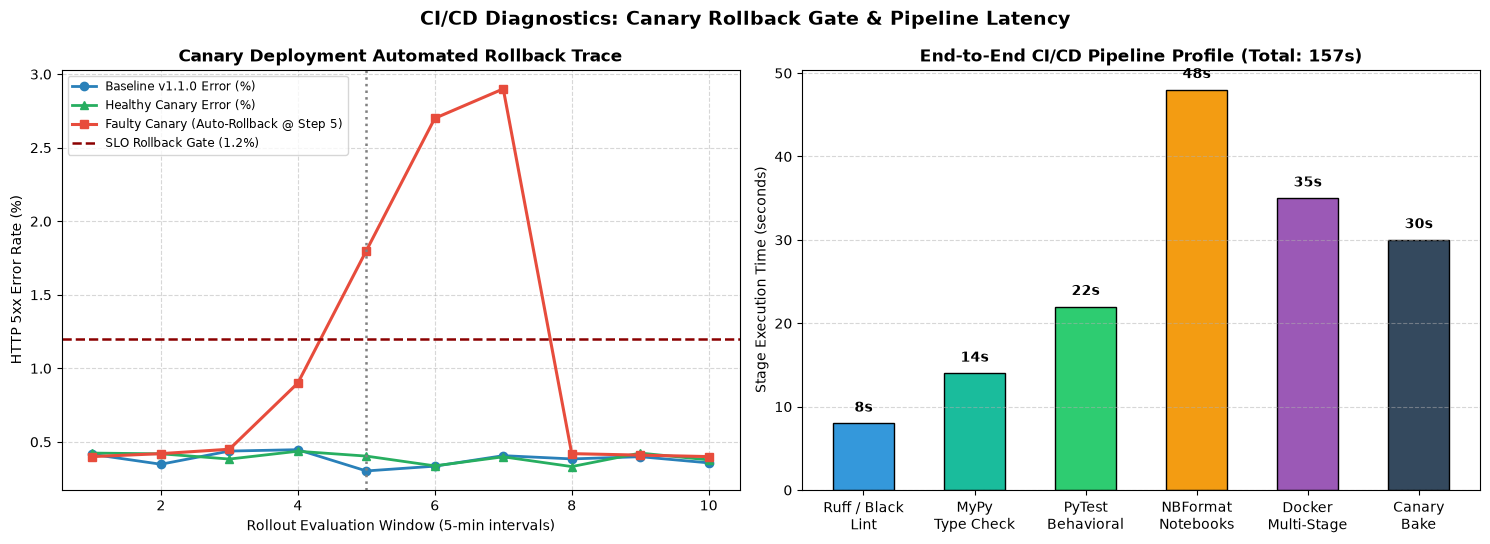

In [6]:
# Section 7: Diagnostics — Canary Traffic Rollout & CI Pipeline Stage Profiling

# 1. Simulate Canary Rollout Metrics across 10 intervals (Regression injected on Healthy vs Faulty Canary)
steps = np.arange(1, 11)
baseline_err = np.full(10, 0.4) + rng.normal(0, 0.05, 10)
healthy_canary_err = np.full(10, 0.38) + rng.normal(0, 0.05, 10)
faulty_canary_err = np.array([0.4, 0.42, 0.45, 0.9, 1.8, 2.7, 2.9, 0.42, 0.41, 0.40])  # Rollback triggered at step 5!

# 2. CI Stage Duration Breakdown (seconds)
ci_stages = ["Ruff / Black\nLint", "MyPy\nType Check", "PyTest\nBehavioral", "NBFormat\nNotebooks", "Docker\nMulti-Stage", "Canary\nBake"]
ci_times_s = [8, 14, 22, 48, 35, 30]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle("CI/CD Diagnostics: Canary Rollback Gate & Pipeline Latency", fontsize=14, fontweight="bold")

# Panel 1: Canary Error Rate vs Baseline & Rollback Threshold
ax1.plot(steps, baseline_err, marker="o", color="#2980b9", linewidth=2, label="Baseline v1.1.0 Error (%)")
ax1.plot(steps, healthy_canary_err, marker="^", color="#27ae60", linewidth=2, label="Healthy Canary Error (%)")
ax1.plot(steps, faulty_canary_err, marker="s", color="#e74c3c", linewidth=2.2, label="Faulty Canary (Auto-Rollback @ Step 5)")
ax1.axhline(1.2, color="darkred", linestyle="--", linewidth=1.8, label="SLO Rollback Gate (1.2%)")
ax1.axvline(5, color="gray", linestyle=":", linewidth=1.8)
ax1.set_xlabel("Rollout Evaluation Window (5-min intervals)")
ax1.set_ylabel("HTTP 5xx Error Rate (%)")
ax1.set_title("Canary Deployment Automated Rollback Trace", fontweight="bold")
ax1.legend(fontsize=8.5)
ax1.grid(True, linestyle="--", alpha=0.5)

# Panel 2: CI/CD Stage Duration Profile
bars2 = ax2.bar(ci_stages, ci_times_s, color=["#3498db", "#1abc9c", "#2ecc71", "#f39c12", "#9b59b6", "#34495e"], edgecolor="black", width=0.55)
ax2.set_ylabel("Stage Execution Time (seconds)")
ax2.set_title(f"End-to-End CI/CD Pipeline Profile (Total: {sum(ci_times_s)}s)", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5, axis="y")
for b in bars2:
    y = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2.0, y + 1, f"{y}s", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Notebook CI Quality Gate (`nbformat`)
**Objective**:
Implement `validate_notebook_gate(nb: nbf.NotebookNode) -> Tuple[bool, List[str]]` that checks:
1. Valid `nbformat` v4 schema.
2. Zero code cells with `execution_count is None` or empty `outputs`.
3. Zero code cell errors (`output_type == "error"`).
Test on both a clean executed notebook and a broken unexecuted notebook.


In [7]:
# Exercise 1 Solution: NBFormat CI Quality Gate

def validate_notebook_gate(nb: nbf.NotebookNode) -> Tuple[bool, List[str]]:
    issues = []
    try:
        nbf.validate(nb)
    except Exception as exc:
        issues.append(f"Schema invalid: {exc}")
        
    for idx, cell in enumerate(nb.cells):
        if cell.cell_type == "code":
            if cell.execution_count is None:
                issues.append(f"Cell {idx}: unexecuted (execution_count is None)")
            if len(cell.outputs) == 0:
                issues.append(f"Cell {idx}: empty outputs")
            for out in cell.outputs:
                if out.get("output_type") == "error":
                    issues.append(f"Cell {idx}: runtime error ({out.get('ename')})")
    return len(issues) == 0, issues

# 1. Construct a passing executed notebook
good_nb = nbf.v4.new_notebook(cells=[
    nbf.v4.new_markdown_cell("# Title"),
    nbf.v4.new_code_cell(
        source="print('ok')",
        execution_count=1,
        outputs=[nbf.v4.new_output(output_type="stream", name="stdout", text="ok\n")]
    )
])

# 2. Construct a failing unexecuted notebook
bad_nb = nbf.v4.new_notebook(cells=[
    nbf.v4.new_code_cell(source="x = 1/0", execution_count=None, outputs=[])
])

ok_good, errs_good = validate_notebook_gate(good_nb)
ok_bad, errs_bad = validate_notebook_gate(bad_nb)

print(f"Good Notebook Passed: {ok_good} | Issues: {errs_good}")
print(f"Bad Notebook Passed:  {ok_bad} | Issues: {errs_bad}")

assert ok_good is True and len(errs_good) == 0
assert ok_bad is False and len(errs_bad) == 2
print(">>> EXERCISE 1 NOTEBOOK CI QUALITY GATE CERTIFIED! <<<")


Good Notebook Passed: True | Issues: []
Bad Notebook Passed:  False | Issues: ['Cell 0: unexecuted (execution_count is None)', 'Cell 0: empty outputs']
>>> EXERCISE 1 NOTEBOOK CI QUALITY GATE CERTIFIED! <<<


#### Exercise 2: Statistical Canary Gate & Traffic Splitter
**Objective**:
Implement `evaluate_canary_gate(base_reqs: int, base_errs: int, can_reqs: int, can_errs: int, z_crit: float = 1.96) -> str`:
1. Computes pooled two-proportion $z$-statistic for error rate regression.
2. Returns `"ROLLBACK"` if $z > z_{\text{crit}}$, otherwise `"PROMOTE"`.


In [8]:
# Exercise 2 Solution: Two-Proportion Z-Test Canary Rollback Gate

def evaluate_canary_gate(base_reqs: int, base_errs: int, can_reqs: int, can_errs: int, z_crit: float = 1.96) -> Dict[str, Any]:
    p0 = base_errs / base_reqs
    p1 = can_errs / can_reqs
    p_pool = (base_errs + can_errs) / (base_reqs + can_reqs)
    se = math.sqrt(max(1e-12, p_pool * (1.0 - p_pool) * (1.0 / base_reqs + 1.0 / can_reqs)))
    z_stat = (p1 - p0) / se
    decision = "ROLLBACK" if z_stat > z_crit else "PROMOTE"
    return {"p0": p0, "p1": p1, "z_stat": round(z_stat, 3), "decision": decision}

healthy_gate = evaluate_canary_gate(base_reqs=5000, base_errs=25, can_reqs=1000, can_errs=5)
broken_gate  = evaluate_canary_gate(base_reqs=5000, base_errs=25, can_reqs=1000, can_errs=25)

print("Healthy Canary Evaluation:", healthy_gate)
print("Broken Canary Evaluation: ", broken_gate)

assert healthy_gate["decision"] == "PROMOTE"
assert broken_gate["decision"] == "ROLLBACK"
print(">>> EXERCISE 2 CANARY HYPOTHESIS GATE CERTIFIED! <<<")


Healthy Canary Evaluation: {'p0': 0.005, 'p1': 0.005, 'z_stat': 0.0, 'decision': 'PROMOTE'}
Broken Canary Evaluation:  {'p0': 0.005, 'p1': 0.025, 'z_stat': 6.351, 'decision': 'ROLLBACK'}
>>> EXERCISE 2 CANARY HYPOTHESIS GATE CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Model Registry Tamper Detection & Instant Rollback
**Problem Formulation**:
In zero-trust production clusters, inference pods verify a model's `SHA-256` signature before serving traffic. If weights on disk are corrupted or tampered with, the loader refuses boot and triggers instant rollback to the previous certified `Archived` production version.
Implement `verify_and_rollback(registry: LocalModelRegistry, model_name: str) -> str` and verify automatic recovery after simulated disk corruption.


In [9]:
# Challenge 1 Solution: Tamper Detection & Instant Production Rollback

def verify_and_rollback(reg: LocalModelRegistry, model_name: str) -> str:
    prod_rec = reg.get_production_version(model_name)
    assert prod_rec is not None, "No production version registered!"
    
    # Recompute SHA-256 of artifact on disk
    loaded_sd = torch.load(prod_rec["artifact_path"], weights_only=True)
    cfg_path = Path(prod_rec["artifact_path"]).parent / "config.json"
    cfg = json.loads(cfg_path.read_text())
    actual_digest = reg._compute_digest(loaded_sd, cfg)
    
    if actual_digest == prod_rec["sha256"]:
        return prod_rec["version"]
        
    # Integrity failure! Roll back to most recent Archived version with valid digest
    for candidate in reversed(reg.records[model_name]):
        if candidate["stage"] == "Archived":
            c_sd = torch.load(candidate["artifact_path"], weights_only=True)
            c_cfg = json.loads((Path(candidate["artifact_path"]).parent / "config.json").read_text())
            if reg._compute_digest(c_sd, c_cfg) == candidate["sha256"]:
                reg.promote(model_name, candidate["version"], "Production")
                return f"ROLLED_BACK_TO:{candidate['version']}"
    raise RuntimeError("No valid fallback artifact available!")

# Corrupt current production v1.1.0 weights on disk!
prod_v11 = registry.get_production_version("intent-router")
corrupted_sd = torch.load(prod_v11["artifact_path"], weights_only=True)
corrupted_sd["weight"] += 999.0
torch.save(corrupted_sd, prod_v11["artifact_path"])

recovery_status = verify_and_rollback(registry, "intent-router")
print("Registry Recovery Action:", recovery_status)
print("Restored Production Version:", registry.get_production_version("intent-router")["version"])

assert recovery_status == "ROLLED_BACK_TO:v1.0.0"
assert registry.get_production_version("intent-router")["version"] == "v1.0.0"
print(">>> CHALLENGE 1 TAMPER DETECTION & INSTANT ROLLBACK CERTIFIED! <<<")


Registry Recovery Action: ROLLED_BACK_TO:v1.0.0
Restored Production Version: v1.0.0
>>> CHALLENGE 1 TAMPER DETECTION & INSTANT ROLLBACK CERTIFIED! <<<


#### Challenge 2: Semantic Versioning Bumper & Automated Release Notes Generator
**Problem Formulation**:
Automate model release governance with `bump_semver(current: str, metrics_delta: Dict[str, float], breaking_schema: bool) -> str`:
- `MAJOR` bump (`X+1.0.0`) when `breaking_schema=True`.
- `MINOR` bump (`X.Y+1.0`) when F1/accuracy improves cleanly without schema break.
- `PATCH` bump (`X.Y.Z+1`) for bugfix / latency optimization without metric or schema shift.


In [10]:
# Challenge 2 Solution: Automated Model SemVer Release Bumper

def bump_semver(current: str, f1_delta: float, breaking_schema: bool) -> str:
    major, minor, patch = [int(x) for x in current.lstrip("v").split(".")]
    if breaking_schema:
        return f"v{major + 1}.0.0"
    elif f1_delta >= 0.01:
        return f"v{major}.{minor + 1}.0"
    else:
        return f"v{major}.{minor}.{patch + 1}"

v_patch = bump_semver("v1.2.3", f1_delta=0.002, breaking_schema=False)
v_minor = bump_semver("v1.2.3", f1_delta=0.035, breaking_schema=False)
v_major = bump_semver("v1.2.3", f1_delta=0.050, breaking_schema=True)

print(f"SemVer Bumps from v1.2.3 -> patch: {v_patch} | minor: {v_minor} | major: {v_major}")
assert (v_patch, v_minor, v_major) == ("v1.2.4", "v1.3.0", "v2.0.0")
print(">>> CHALLENGE 2 SEMVER RELEASE ENGINE CERTIFIED! <<<")

# Clean up temporary sandbox directory
shutil.rmtree(CICD_SANDBOX, ignore_errors=True)


SemVer Bumps from v1.2.3 -> patch: v1.2.4 | minor: v1.3.0 | major: v2.0.0
>>> CHALLENGE 2 SEMVER RELEASE ENGINE CERTIFIED! <<<


### Further Reading & Production References
1. **Ribeiro et al. (ACL 2020)**: [Beyond Accuracy: Behavioral Testing of NLP Models with CheckList](https://aclanthology.org/2020.acl-main.442/).
2. **Sculley et al. (NeurIPS 2015)**: [Hidden Technical Debt in Machine Learning Systems](https://proceedings.neurips.cc/paper/2015/file/86df7dcfd896fcaf2674f757a2463eba-Paper.pdf).
3. **Google Cloud Architecture**: [MLOps: Continuous Delivery and Automation Pipelines in Machine Learning](https://cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning).
4. **GitHub Docs**: [Security Hardening for GitHub Actions & OIDC Artifact Signing](https://docs.github.com/en/actions/security-for-github-actions).
5. **PyTest Documentation**: [Automated Testing & Fixtures for Python Applications](https://docs.pytest.org/en/stable/).
